In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
from tqdm import tqdm
import tifffile
from ipywidgets import HBox, VBox

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon Graphics (RADV REMBRANDT),IntegratedGPU,Vulkan,Mesa 22.3.6
✅ (default),NVIDIA T1200 Laptop GPU,DiscreteGPU,Vulkan,535.129.03
❗ limited,"llvmpipe (LLVM 15.0.6, 256 bits)",CPU,Vulkan,Mesa 22.3.6 (LLVM 15.0.6)
❌,"AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
from skophys.utils import rolling_percentile

/home/kushal/venvs/fpl/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [3]:
%matplotlib inline

In [4]:
path = "./demo_movie_mcorr.tiff"
movie = tifffile.imread(path)

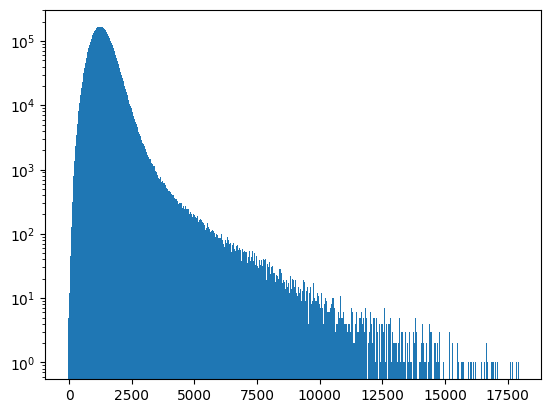

In [5]:
plt.hist(movie.ravel(), bins=1_000)
plt.semilogy()
plt.show()

In [6]:
def mean_psd(y, method='logmexp'):
    """
    Averaging the PSD

    Args:
        y: np.ndarray
             PSD values

        method: string
            method of averaging the noise.
            Choices:
             'mean': Mean
             'median': Median
             'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        mp: array
            mean psd
    """

    if method == 'mean':
        mp = np.sqrt(np.mean(y / 2, axis=-1))
    elif method == 'median':
        mp = np.sqrt(np.median(y / 2, axis=-1))
    else:
        mp = np.log((y + 1e-10) / 2)
        mp = np.mean(mp, axis=-1)
        mp = np.exp(mp)
        mp = np.sqrt(mp)

    return mp

def get_noise_fft(Y, noise_range=[0.25, 0.5], noise_method='logmexp', max_num_samples_fft=3072,
                  opencv=True):
    """Estimate the noise level for each pixel by averaging the power spectral density.

    Args:
        Y: np.ndarray
            Input movie data with time in the last axis

        noise_range: np.ndarray [2 x 1] between 0 and 0.5
            Range of frequencies compared to Nyquist rate over which the power spectrum is averaged
            default: [0.25,0.5]

        noise method: string
            method of averaging the noise.
            Choices:
                'mean': Mean
                'median': Median
                'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        sn: np.ndarray
            Noise level for each pixel
    """
    T = Y.shape[-1]
    # Y=np.array(Y,dtype=np.float64)

    if T > max_num_samples_fft:
        Y = np.concatenate((Y[..., 1:max_num_samples_fft // 3 + 1],
                            Y[..., int(T // 2 - max_num_samples_fft / 3 / 2)
                                          :int(T // 2 + max_num_samples_fft / 3 / 2)],
                            Y[..., -max_num_samples_fft // 3:]), axis=-1)
        T = np.shape(Y)[-1]

    # we create a map of what is the noise on the FFT space
    ff = np.arange(0, 0.5 + 1. / T, 1. / T)
    ind1 = ff > noise_range[0]
    ind2 = ff <= noise_range[1]
    ind = np.logical_and(ind1, ind2)
    # we compute the mean of the noise spectral density s
    if Y.ndim > 1:
        if opencv:
            import cv2
            try:
                cv2.setNumThreads(0)
            except:
                pass
            psdx_list = []
            for y in Y.reshape(-1, T):
                dft = cv2.dft(y, flags=cv2.DFT_COMPLEX_OUTPUT).squeeze()[
                    :len(ind)][ind]
                psdx_list.append(np.sum(1. / T * dft * dft, 1))
            psdx = np.reshape(psdx_list, Y.shape[:-1] + (-1,))
        else:
            xdft = np.fft.rfft(Y, axis=-1)
            xdft = xdft[..., ind[:xdft.shape[-1]]]
            psdx = 1. / T * abs(xdft)**2
        psdx *= 2
        sn = mean_psd(psdx, method=noise_method)

    else:
        xdft = np.fliplr(np.fft.rfft(Y))
        psdx = 1. / T * (xdft**2)
        psdx[1:] *= 2
        sn = mean_psd(psdx[ind[:psdx.shape[0]]], method=noise_method)

    return sn, psdx

In [7]:
sn, psdx = get_noise_fft(movie.T)

movie /= sn.T

In [8]:
iw_movie = fpl.ImageWidget(movie, cmap="viridis")
tfig = fpl.Figure()

raw_trace = tfig[0, 0].add_line(np.zeros(movie.shape[0]))

@iw_movie.managed_graphics[0].add_event_handler("click")
def pixel_clicked(ev):
    col, row = ev.pick_info["index"]
    raw_trace.data[:, 1] =  iw_movie.data[0][:, row, col]
    tfig[0, 0].auto_scale(maintain_aspect=False)

HBox([iw_movie.show(), tfig.show()])

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [7]:
iw_movie.window_funcs = {"t": (np.mean, 11)}

In [9]:
filt_movie = rolling_percentile(movie, window_size=5, quantile=5)

In [9]:
iw_movie.set_data(filt_movie, reset_indices=False)

In [10]:
from sklearn.preprocessing import RobustScaler

In [11]:
filt_movie.shape

(2000, 60, 80)

In [14]:
Y = filt_movie.T.reshape(np.prod(filt_movie.shape[1:]), filt_movie.shape[0])

In [15]:
ss = RobustScaler()

In [16]:
Y = ss.fit_transform(Y.T)
Y = Y.T

In [ ]:
iw_movie.set_data(Y.reshape(movie.shape[2], movie.shape[1], movie.shape[0]).T, reset_indices=False)

In [17]:
Y

array([[-0.89419097, -0.89419097, -0.8748388 , ...,  0.2051251 ,
         1.6246736 , -4.1461906 ],
       [-0.95727205, -0.9679052 , -0.9679052 , ...,  1.8111186 ,
         1.9022065 , -3.7743917 ],
       [-0.7453565 , -0.9085403 , -0.9085403 , ...,  2.9132311 ,
         2.8679678 , -3.8930056 ],
       ...,
       [ 0.02373504,  0.02373504,  0.03461298, ...,  1.0995506 ,
         1.0857149 , -2.9637275 ],
       [-0.64975953, -0.64975953, -0.6976371 , ...,  0.75527513,
         0.8615381 , -3.0577042 ],
       [-1.0373353 , -1.0373353 , -0.56953984, ...,  0.8750072 ,
         2.248134  , -3.2532547 ]], dtype=float32)

In [21]:
Y = Y[:, :-1]

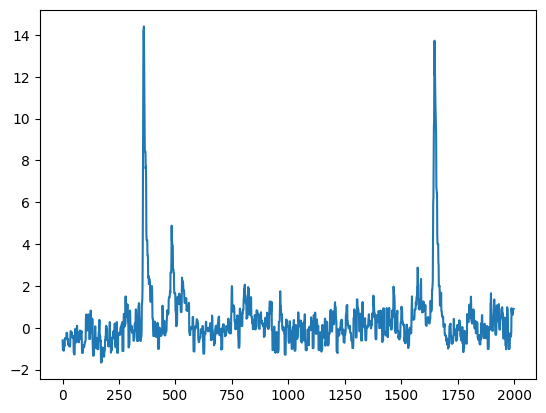

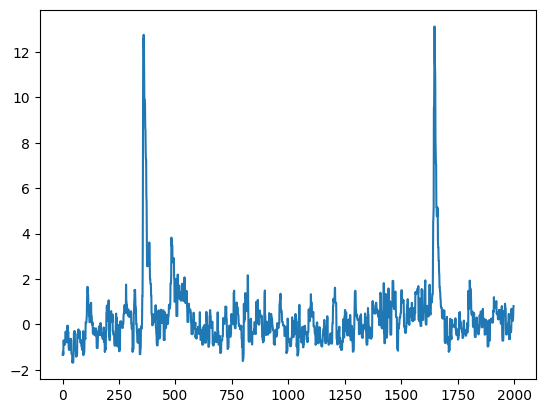

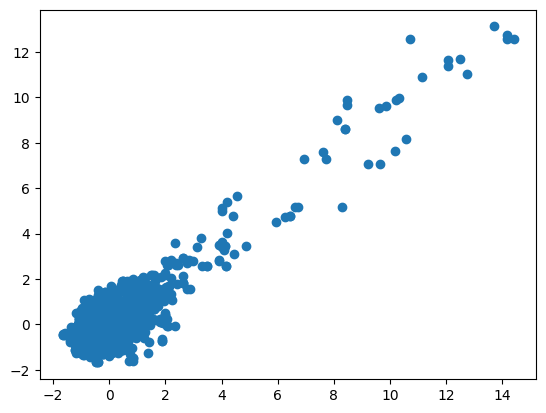

In [22]:
i1 = 1302
i2 = 1303

u = Y[i1]
v = Y[i2]

plt.plot(u)
plt.show()
plt.plot(v)
plt.show()

plt.scatter(Y[i1, :], Y[i2, :])
plt.show()
# plt.scatter(projections[:, 0], projections[:, 1])

In [23]:
Y.shape

(4800, 1999)

In [24]:
from numba import guvectorize, float64, int64, float32, prange, njit
from itertools import product

In [25]:
@njit(parallel=True)
def get_distances(
    i: int, 
    Y: np.ndarray, 
    ysum: np.ndarray, 
    projections: np.ndarray,
    output: np.ndarray
):
    for j in prange(Y.shape[0]):
        i_dot_j = np.dot(Y[i], Y[j])
        i_dot_i = np.dot(Y[i], Y[i])
        m = (i_dot_j - 1 / Y.shape[1] * ysum[i] * ysum[j]) / (i_dot_i - 1 / Y.shape[1] * ysum[i]**2)
        
        v1 = np.array([m, 1])

        x = Y[i, :]
        y = Y[j, :]
        
        # Step 1: Calculate means of x and y
        x_mean = np.mean(x)
        y_mean = np.mean(y)
        
        v1[0] += x_mean
        v1[1] += y_mean

        denom = np.sqrt(v1.sum())
        v1[0] = v1[0] / denom
        v1[1] = v1[1] / denom

        v1 /= np.sqrt(np.sum(v1**2))
        
        X = np.zeros((x.size, 2))
        X[:, 0] = x
        X[:, 1] = y
        
        projections_pre = (X @ v1)
        
        projections[j, :, 0] = projections_pre * v1[0]
        projections[j, :, 1] = projections_pre * v1[1]

        orthogonal_distances = X - projections[j]  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)
        # orthogonal_distances = orthogonal_distances**2
        
        # # # Sum of orthogonal distances
        # sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000

        output[j] = s**2

In [26]:
Y_squared = Y
ysum = np.sum(Y_squared, axis=1)
projections = np.zeros((*Y.shape, 2))
output_matrix = np.zeros((Y.shape[0],))

In [27]:
get_distances(
    2500,
    Y_squared,
    ysum,
    projections,
    output_matrix
)

/tmp/ipykernel_974184/1078253701.py:10: NumbaPerformanceWarning: np.dot() is faster on contiguous arrays, called on (Array(float32, 1, 'A', False, aligned=True), Array(float32, 1, 'A', False, aligned=True))
  i_dot_j = np.dot(Y[i], Y[j])


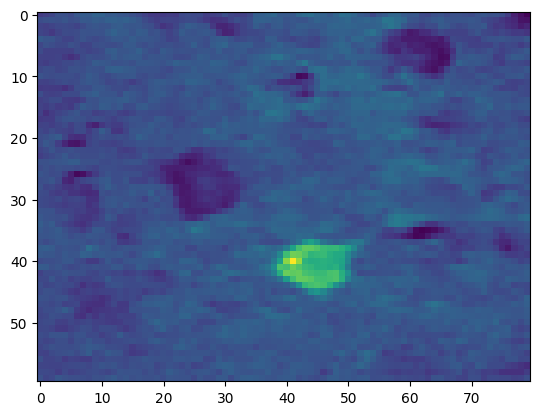

In [28]:
plt.imshow(output_matrix.reshape(movie.shape[2], movie.shape[1]).T, cmap="viridis_r")
plt.show()

In [29]:
projections.shape

(4800, 1999, 2)

In [30]:
std = filt_movie.std(axis=0)

In [31]:
iw = fpl.ImageWidget([std, np.zeros(std.shape)], cmap="viridis")

pixel_index_A = 0
projections = np.zeros((*Y.shape, 2))

pixel_A_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="magenta")
pixel_B_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="cyan")

@iw.managed_graphics[0].add_event_handler("double_click")
def update_distance_image(ev):
    global pixel_index_A
    global projections
    
    col, row = ev.pick_info["index"]

    i = np.ravel_multi_index((col, row), (movie.shape[2], movie.shape[1]))
    
    pixel_index_A = i

    pixel_A_pt.data[0, 0] = col
    pixel_A_pt.data[0, 1] = row
    
    output_matrix = np.zeros((Y.shape[0],))
    projections = np.zeros((*Y.shape, 2))
    get_distances(
        i,
        Y,
        ysum,
        projections,
        output_matrix
    )
    
    iw.managed_graphics[1].data = output_matrix.reshape(movie.shape[2], movie.shape[1]).T
    iw.reset_vmin_vmax()


fig_s = fpl.Figure(shape=(1, 2))

scatter_corr = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors=(1, 0.7, 0, 0.3), alpha=0.3)
scatter_proj = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors="r", alpha=0.3)
fig_s[0, 0].axes.colors = ("magenta", "cyan", "w")

line_p1 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="magenta", alpha=0.3)
line_p2 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="cyan", alpha=0.3)

selector_time = line_p1.add_linear_selector()

@iw.managed_graphics[1].add_event_handler("double_click")
def update_scatters(ev):
    u = Y[pixel_index_A]

    col, row = ev.pick_info["index"]

    j = np.ravel_multi_index((col, row), (movie.shape[2], movie.shape[1]))
    v = Y[j]

    pixel_B_pt.data[0, 0] = col
    pixel_B_pt.data[0, 1] = row
    
    scatter_corr.data[:, :-1] = np.column_stack([u, v])
    scatter_proj.data[:, :-1] = projections[j]
    fig_s[0, 0].auto_scale(maintain_aspect=False)

    line_p1.data[:, 1] = u
    line_p2.data[:, 1] = v
    fig_s[0, 1].auto_scale(maintain_aspect=False)

@selector_time.add_event_handler("selection")
def update_selected_time(ev):
    t = ev.get_selected_index()
    scatter_corr.colors = (1, 0.7, 0, 0.3)
    scatter_corr.sizes = 4
    
    scatter_corr.colors[t] = "w"
    scatter_corr.sizes[t] = 20


iw.cmap = ["viridis", "viridis_r"]

VBox([iw.show(), fig_s.show(maintain_aspect=False)])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

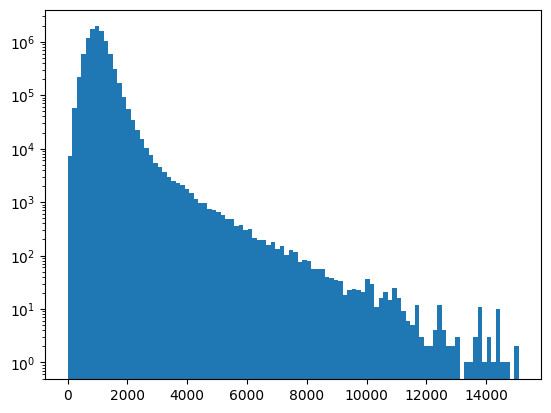

In [102]:
plt.hist(filt_movie.ravel(), bins=100)
plt.semilogy()
plt.show()

In [103]:
iw.managed_graphics[1].vmax = np.percentile(iw.managed_graphics[1].data[:], 3)

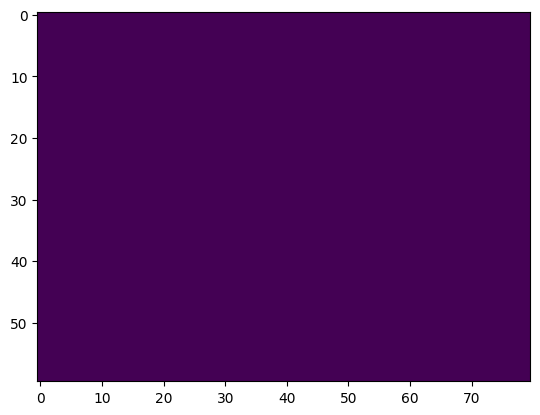

In [104]:
plt.imshow(iw.managed_graphics[1].data[:] < np.percentile(iw.managed_graphics[1].data[:], 2))

In [105]:
np.percentile(iw.managed_graphics[1].data[:], 3)

np.float32(0.0)

In [106]:
i_col, i_row, _ =  pixel_A_pt.data[0]
i_col, i_row

(np.float32(0.0), np.float32(0.0))

In [107]:
j_col, j_row, _ = pixel_B_pt.data[0]
j_col, j_row

(np.float32(0.0), np.float32(0.0))

# Plot time series of the two pixels, linear region selector to highlight scatter point
# click on scatter point, set linear region selector timepoint

In [108]:
Y.shape

(4800, 2000)

In [109]:
dist_cov = np.zeros((Y.shape[0], Y.shape[0]), dtype=np.float32)

In [110]:
for i in tqdm(range(Y.shape[0])):
    output_matrix = np.zeros((Y.shape[0],))
    get_distances(
        i,
        Y,
        ysum,
        projections,
        output_matrix
    )
    dist_cov[i] = output_matrix

 16%|██████████████▍                                                                         | 787/4800 [00:11<00:57, 69.84it/s]


KeyboardInterrupt: 

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas(css_height='400px', css_width='700px')
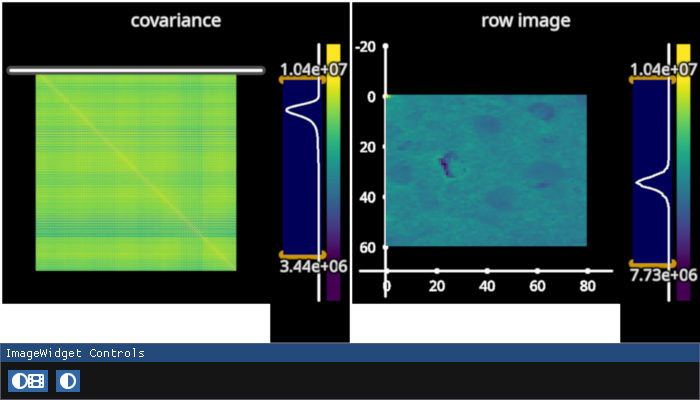

In [40]:
dist_cov -= dist_cov.max()
dist_cov = np.abs(dist_cov)

img = dist_cov[0].reshape(movie.shape[2], movie.shape[1])

figure_kwargs = {"size": (700, 400), "controller_ids": [[0, 1]]}
iw_cov = fpl.ImageWidget(
    data=[dist_cov, img.T],
    names=["covariance", "row image"],
    figure_kwargs=figure_kwargs,
)

iw_cov.cmap = ["viridis", "viridis"]

selector_cov = iw_cov.managed_graphics[0].add_linear_selector(axis="y")

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()
    img = dist_cov[ix].reshape(movie.shape[2], movie.shape[1])
    iw_cov.managed_graphics[1].data = img.T

iw_cov.show()

In [88]:
Y.shape

(4800, 2000)

In [265]:
clusters = np.zeros((100, Y.shape[0]), dtype=np.int32)

In [285]:
for i in tqdm(range(1100, 2200)):
    # see if this pixel is never active
    if np.count_nonzero(Y[i] > 5) < 3:
        continue
    
    threshold = np.percentile(dist_cov[i], 3)

    # does this pixel already belong to any existing cluster(s)
    cluster_memberships = np.where(clusters[:, i] != 0)[0]
    if cluster_memberships.size == 0:
        # create new cluster index for this pixel and keep if matches are found
        for n in range(clusters.shape[0]):
            if (clusters[n, :] == 0).all():
                break
                
        membership_indices = np.array([n])
    else:
        membership_indices = cluster_memberships
    
    for j in range(1100, 2200):
        # check if pixel is active
        if np.count_nonzero(Y[j] > 5) < 3:
            continue

        if dist_cov[i, j] < threshold:
            # add i and j to this cluster
            clusters[membership_indices, j] = 1
            flag_match = True
            
    if flag_match:
        clusters[membership_indices, i] = 1

100%|███████████████████████████████████████████████████████████████████| 1100/1100 [00:00<00:00, 1994.39it/s]


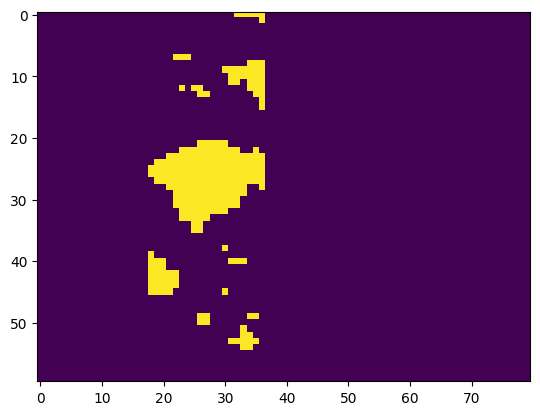

In [286]:
plt.imshow(clusters[0].reshape(movie.shape[2], movie.shape[1]).T)

In [38]:
from sklearn.cluster import SpectralClustering

In [79]:
sc = SpectralClustering(n_clusters=10, affinity="precomputed", assign_labels="kmeans")

In [80]:
sc.fit_predict(dist_cov)

/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)


array([1, 9, 9, ..., 8, 8, 8], dtype=int32)

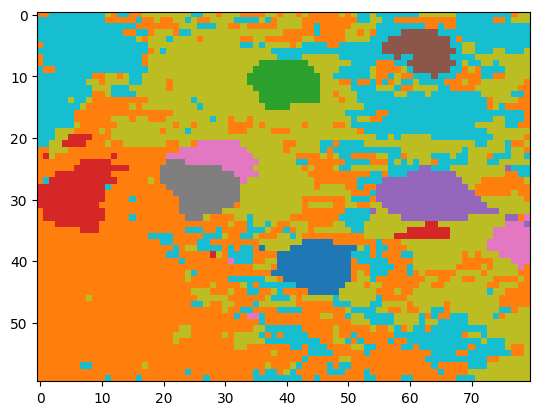

In [81]:
plt.imshow(sc.labels_.reshape(movie.shape[2], movie.shape[1]).T, cmap="tab10")

In [51]:
from sklearn.metrics import davies_bouldin_score

In [57]:
scores = list()

for n in range(2, 20):
    sc = SpectralClustering(n_clusters=n, affinity="precomputed", assign_labels="cluster_qr")
    sc.fit_predict(dist_cov)
    score = davies_bouldin_score(Y, sc.labels_)
    scores.append(score)

/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)
/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)
/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)
/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)
/home/kushal/venvs/fpl/lib/python3.1

([<matplotlib.axis.XTick at 0x7eff25d41310>,
 [Text(0, 0, '2'),
  Text(1, 0, '3'),
  Text(2, 0, '4'),
  Text(3, 0, '5'),
  Text(4, 0, '6'),
  Text(5, 0, '7'),
  Text(6, 0, '8'),
  Text(7, 0, '9'),
  Text(8, 0, '10'),
  Text(9, 0, '11'),
  Text(10, 0, '12'),
  Text(11, 0, '13'),
  Text(12, 0, '14'),
  Text(13, 0, '15'),
  Text(14, 0, '16'),
  Text(15, 0, '17'),
  Text(16, 0, '18'),
  Text(17, 0, '19')])

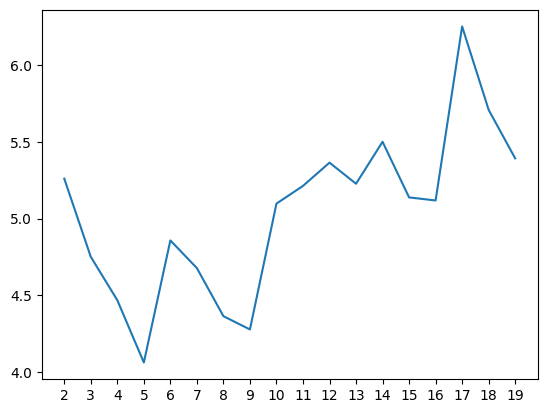

In [60]:
plt.plot(scores)
plt.xticks(range(0, 18), range(2, 20))